In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
project_path = "/content/drive/MyDrive/Saama/patient-dropout-event-forecasting/patient-dropout-event-forecasting"

In [ ]:
import pandas as pd
X_train = pd.read_csv(f"{project_path}/Phase4/train_x.csv")
y_train = pd.read_csv(f"{project_path}/Phase4/train_y.csv")
X_test = pd.read_csv(f"{project_path}/Phase4/test_x.csv")
y_test = pd.read_csv(f"{project_path}/Phase4/test_y.csv")

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

X_train shape: (5503, 61)
y_train shape: (5503, 3)
X_test shape : (1364, 61)
y_test shape : (1364, 3)


In [ ]:
X_train.head()

,Unnamed: 0,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,...,smiless,sponsors/lead_sponsor/agency_class,study_design_info/allocation,study_design_info/intervention_model,study_design_info/intervention_model_description,study_design_info/masking,study_design_info/masking_description,study_design_info/masking_num,study_design_info/primary_purpose,study_type
0,NCT03050294,2.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,...,['[H][C@@]12C[C@@H](C)[C@H](C(=O)CO)[C@@]1(C)C...,Other,Randomized,Parallel Assignment,NaN,None (Open Label),NaN,0.0,Treatment,Interventional
1,NCT02634983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,NaN,Industry,Randomized,Crossover Assignment,NaN,"Double (Participant, Investigator)",NaN,2.0,Treatment,Interventional
2,NCT00352612,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,...,['[H][C@@](NC(=O)[C@@H]1C[C@@H](CCC)CN1C)([C@H...,Other,Randomized,Parallel Assignment,NaN,"Double (Participant, Care Provider)",NaN,2.0,Treatment,Interventional
3,NCT02107339,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,['CCC(=O)C(CC(C)N(C)C)(C1=CC=CC=C1)C1=CC=CC=C1...,Other,Randomized,Parallel Assignment,NaN,"Quadruple (Participant, Care Provider, Investi...",NaN,4.0,Treatment,Interventional
4,NCT00190775,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,...,['CNCC[C@@H](OC1=CC=CC=C1C)C1=CC=CC=C1'],Industry,Randomized,Parallel Assignment,NaN,"Triple (Participant, Investigator, Outcomes As...",NaN,3.0,Treatment,Interventional


In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5503 entries, 0 to 5502
Data columns (total 61 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Unnamed: 0                                        5503 non-null   object 
 1   Active Comparator Arm Number                      5450 non-null   float64
 2   Behavioral intervention Number                    5503 non-null   float64
 3   Biological intervention Number                    5503 non-null   float64
 4   Combination Product intervention Number           5503 non-null   float64
 5   Device intervention Number                        5503 non-null   float64
 6   Diagnostic Test intervention Number               5503 non-null   float64
 7   Dietary Supplement intervention Number            5503 non-null   float64
 8   Drug intervention Number                          5503 non-null   float64
 9   Experimental Arm Nu

In [ ]:
X_train.describe()

,Active Comparator Arm Number,Behavioral intervention Number,Biological intervention Number,Combination Product intervention Number,Device intervention Number,Diagnostic Test intervention Number,Dietary Supplement intervention Number,Drug intervention Number,Experimental Arm Number,Genetic intervention Number,...,Radiation intervention Number,Sham Comparator Arm Number,enrollment,ipd_info_type-Analytic Code,ipd_info_type-Clinical Study Report (CSR),ipd_info_type-Informed Consent Form (ICF),ipd_info_type-Statistical Analysis Plan (SAP),ipd_info_type-Study Protocol,number_of_arms,study_design_info/masking_num
count,5450.000000,5503.000000,5503.000000,5503.000000,5503.000000,5503.000000,5503.000000,5503.000000,5450.000000,5503.000000,...,5503.000000,5450.000000,5503.000000,175.000000,175.000000,175.000000,175.000000,175.000000,5450.000000,5495.000000
mean,0.686239,0.038524,0.106487,0.003089,0.103762,0.002362,0.017445,1.689260,0.935046,0.000909,...,0.001817,0.006422,383.517536,0.137143,0.697143,0.508571,0.885714,0.988571,2.046422,1.296087
std,0.901200,0.271590,0.459877,0.069984,0.418960,0.067366,0.182038,1.237562,1.167635,0.035657,...,0.046666,0.079887,5743.446910,0.344985,0.460812,0.501361,0.319071,0.106597,1.165137,1.537143
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,29.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,...,0.000000,0.000000,68.000000,0.000000,1.000000,1.000000,1.000000,1.000000,2.000000,0.000000
75%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,...,0.000000,0.000000,178.000000,0.000000,1.000000,1.000000,1.000000,1.000000,2.000000,3.000000
max,8.000000,5.000000,10.000000,3.000000,6.000000,3.000000,5.000000,14.000000,32.000000,2.000000,...,2.000000,1.000000,353323.000000,1.000000,1.000000,1.000000,1.000000,1.000000,32.000000,4.000000


In [ ]:
y_train.head()

,Unnamed: 0,droupout_rate,Y/N
0,NCT03050294,0.000000,0
1,NCT02634983,0.064516,1
2,NCT00352612,0.000000,0
3,NCT02107339,0.041667,1
4,NCT00190775,0.496016,1


In [ ]:
print(y_train.columns)

Index(['Unnamed: 0', 'droupout_rate', 'Y/N'], dtype='object')


In [ ]:
y_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5503 entries, 0 to 5502
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     5503 non-null   object 
 1   droupout_rate  5503 non-null   float64
 2   Y/N            5503 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 129.1+ KB


In [ ]:
missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

,0
ipd_info_type-Statistical Analysis Plan (SAP),5328
ipd_info_type-Informed Consent Form (ICF),5328
ipd_info_type-Analytic Code,5328
ipd_info_type-Study Protocol,5328
ipd_info_type-Clinical Study Report (CSR),5328
study_design_info/masking_description,5286
study_design_info/intervention_model_description,5137
oversight_info/is_fda_regulated_device,4086
oversight_info/is_fda_regulated_drug,4075
patient_data/sharing_ipd,3580


In [ ]:
missing_percentage = (X_train.isnull().sum() / len(X_train)) * 100
missing_percentage = (
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)
missing_percentage

,0
ipd_info_type-Statistical Analysis Plan (SAP),96.819916
ipd_info_type-Informed Consent Form (ICF),96.819916
ipd_info_type-Analytic Code,96.819916
ipd_info_type-Study Protocol,96.819916
ipd_info_type-Clinical Study Report (CSR),96.819916
study_design_info/masking_description,96.056696
study_design_info/intervention_model_description,93.349082
oversight_info/is_fda_regulated_device,74.250409
oversight_info/is_fda_regulated_drug,74.050518
patient_data/sharing_ipd,65.055424


In [ ]:
X_train.dtypes.value_counts()

,count
object,32
float64,29


In [ ]:
X_train.duplicated().sum()

np.int64(0)

In [ ]:
y_train["droupout_rate"].describe()

,droupout_rate
count,5503.000000
mean,0.156300
std,0.216203
min,0.000000
25%,0.000000
50%,0.076923
75%,0.210526
max,1.000000


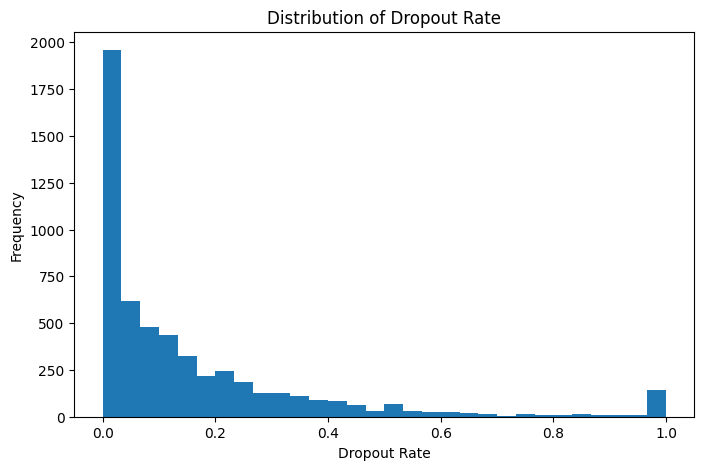

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(y_train["droupout_rate"], bins=30)
plt.xlabel("Dropout Rate")
plt.ylabel("Frequency")
plt.title("Distribution of Dropout Rate")
plt.show()